# 02 — Feature Importance
## Quais features mais influenciam a performance dos posts?

Abordagens:
1. **Correlação Spearman** — relação monotônica entre features e métricas
2. **Random Forest** — feature importance por permutação
3. **Ranking consolidado** — combinando ambas as abordagens

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import cross_val_score

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["figure.dpi"] = 100

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "general_dataset.parquet")
reels = df[df["post_type"] == "REEL"].copy()
print(f"Reels: {len(reels)} posts (foco da análise — tipo dominante com métricas completas)")

Reels: 116 posts (foco da análise — tipo dominante com métricas completas)


## 1. Preparar matriz de features (numéricas + categóricas encodadas)

In [2]:
num_features = [
    "video_duration_sec", "cuts_per_minute", "speech_pacing_wpm",
    "image_quality_score", "curiosity_gap_level", "first_frame_scroll_stop_score",
    "creator_camera_presence_score", "educational_density",
    "controversy_level", "overall_provocation_score",
    "caption_length_chars", "hashtag_count", "account_mentions_count",
]

cat_features = [
    "aspect_ratio", "text_overlay_presence", "dominant_color_palette",
    "lighting_type", "camera_movement_style", "hook_visual_technique",
    "visual_format_type", "transition_style", "face_presence",
    "zoom_effect_used", "thumbnail_composition",
    "audio_hook_type", "text_hook_on_screen", "pattern_interrupt_type",
    "opening_emotion_conveyed", "hook_delivery_speed",
    "direct_viewer_address", "bait_and_reveal_structure",
    "opening_subject_framing", "people_count", "primary_person_age_range",
    "eye_contact_with_camera", "dominant_facial_expression",
    "body_language_energy", "appearance_style",
    "audio_source_type", "voice_tone_energy", "background_music_mood",
    "music_beat_sync", "voice_to_music_balance", "audio_caption_availability",
    "content_category", "narrative_structure", "value_proposition_type",
    "cta_type", "content_originality", "emotional_arc",
    "target_audience_intent", "information_pacing",
    "skin_exposure_level", "hook_sensuality_level", "suggestive_body_language",
    "innuendo_in_text", "caption_first_line_hook", "caption_tone", "emoji_density",
]

all_features = num_features + cat_features
target_metrics = ["reach", "views", "likes", "shares", "saved"]

available_cat = [f for f in cat_features if f in reels.columns and reels[f].notna().sum() > 50]
available_num = [f for f in num_features if f in reels.columns and reels[f].notna().sum() > 50]
available = available_num + available_cat

X = reels[available].copy()

enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X[available_cat] = enc.fit_transform(X[available_cat].fillna("__MISSING__"))

X[available_num] = X[available_num].fillna(X[available_num].median())

print(f"Matriz de features: {X.shape[0]} reels × {X.shape[1]} features")
print(f"  Numéricas: {len(available_num)}")
print(f"  Categóricas: {len(available_cat)}")

Matriz de features: 116 reels × 59 features
  Numéricas: 13
  Categóricas: 46


## 2. Correlação Spearman (todas as features vs métricas)

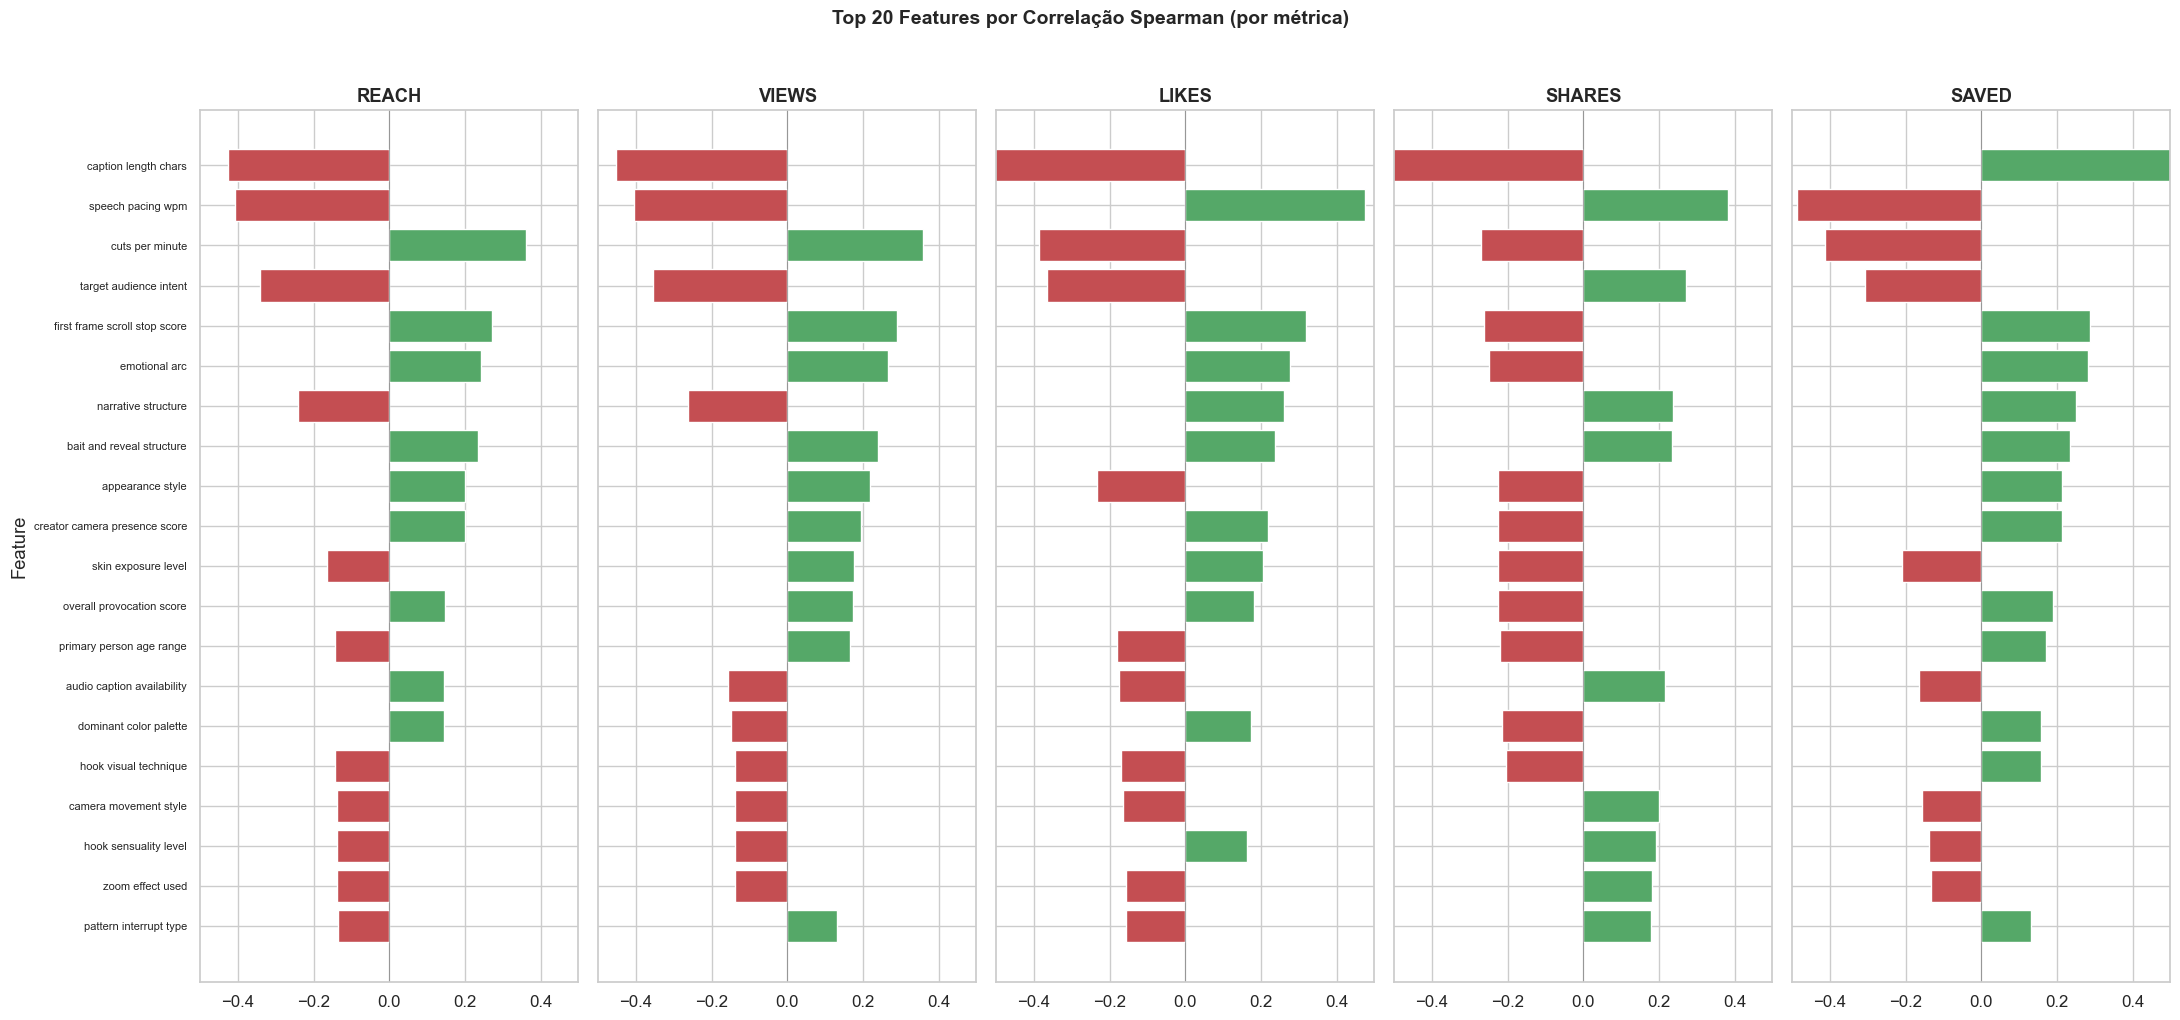

In [3]:
spearman_results = {}

for metric in target_metrics:
    y = reels[metric].values
    corrs = {}
    for feat in available:
        x = X[feat].values
        valid = ~(np.isnan(x) | np.isnan(y))
        if valid.sum() > 10:
            rho, pval = stats.spearmanr(x[valid], y[valid])
            corrs[feat] = {"rho": rho, "pval": pval, "abs_rho": abs(rho)}
    spearman_results[metric] = pd.DataFrame(corrs).T.sort_values("abs_rho", ascending=False)

fig, axes = plt.subplots(1, len(target_metrics), figsize=(22, 10), sharey=True)
for ax, metric in zip(axes, target_metrics):
    top20 = spearman_results[metric].head(20)
    colors = ["#55A868" if r > 0 else "#C44E52" for r in top20["rho"]]
    ax.barh(range(len(top20)), top20["rho"], color=colors, edgecolor="white")
    ax.set_yticks(range(len(top20)))
    labels = [f.replace("_", " ")[:30] for f in top20.index]
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_xlim(-0.5, 0.5)
    ax.set_title(metric.upper(), fontweight="bold")
    if ax == axes[0]:
        ax.set_ylabel("Feature")

fig.suptitle("Top 20 Features por Correlação Spearman (por métrica)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 3. Random Forest — Feature Importance por métrica

In [4]:
rf_results = {}

for metric in target_metrics:
    y = reels[metric].values
    
    rf = RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_leaf=5,
                               random_state=42, n_jobs=-1)
    rf.fit(X.values, y)
    
    cv_scores = cross_val_score(rf, X.values, y, cv=5, scoring="r2")
    
    perm_imp = permutation_importance(rf, X.values, y, n_repeats=20,
                                       random_state=42, n_jobs=-1)
    
    imp_df = pd.DataFrame({
        "feature": available,
        "importance_mean": perm_imp.importances_mean,
        "importance_std": perm_imp.importances_std,
        "gini_importance": rf.feature_importances_,
    }).sort_values("importance_mean", ascending=False)
    
    rf_results[metric] = {"imp": imp_df, "cv_r2": cv_scores}
    print(f"{metric.upper():>8s}:  R² = {cv_scores.mean():.3f} ± {cv_scores.std():.3f} (5-fold CV)")

   REACH:  R² = -73.999 ± 92.757 (5-fold CV)


   VIEWS:  R² = -75.280 ± 94.530 (5-fold CV)


   LIKES:  R² = -115.071 ± 174.035 (5-fold CV)


  SHARES:  R² = -78.317 ± 102.867 (5-fold CV)


   SAVED:  R² = -26.314 ± 48.197 (5-fold CV)


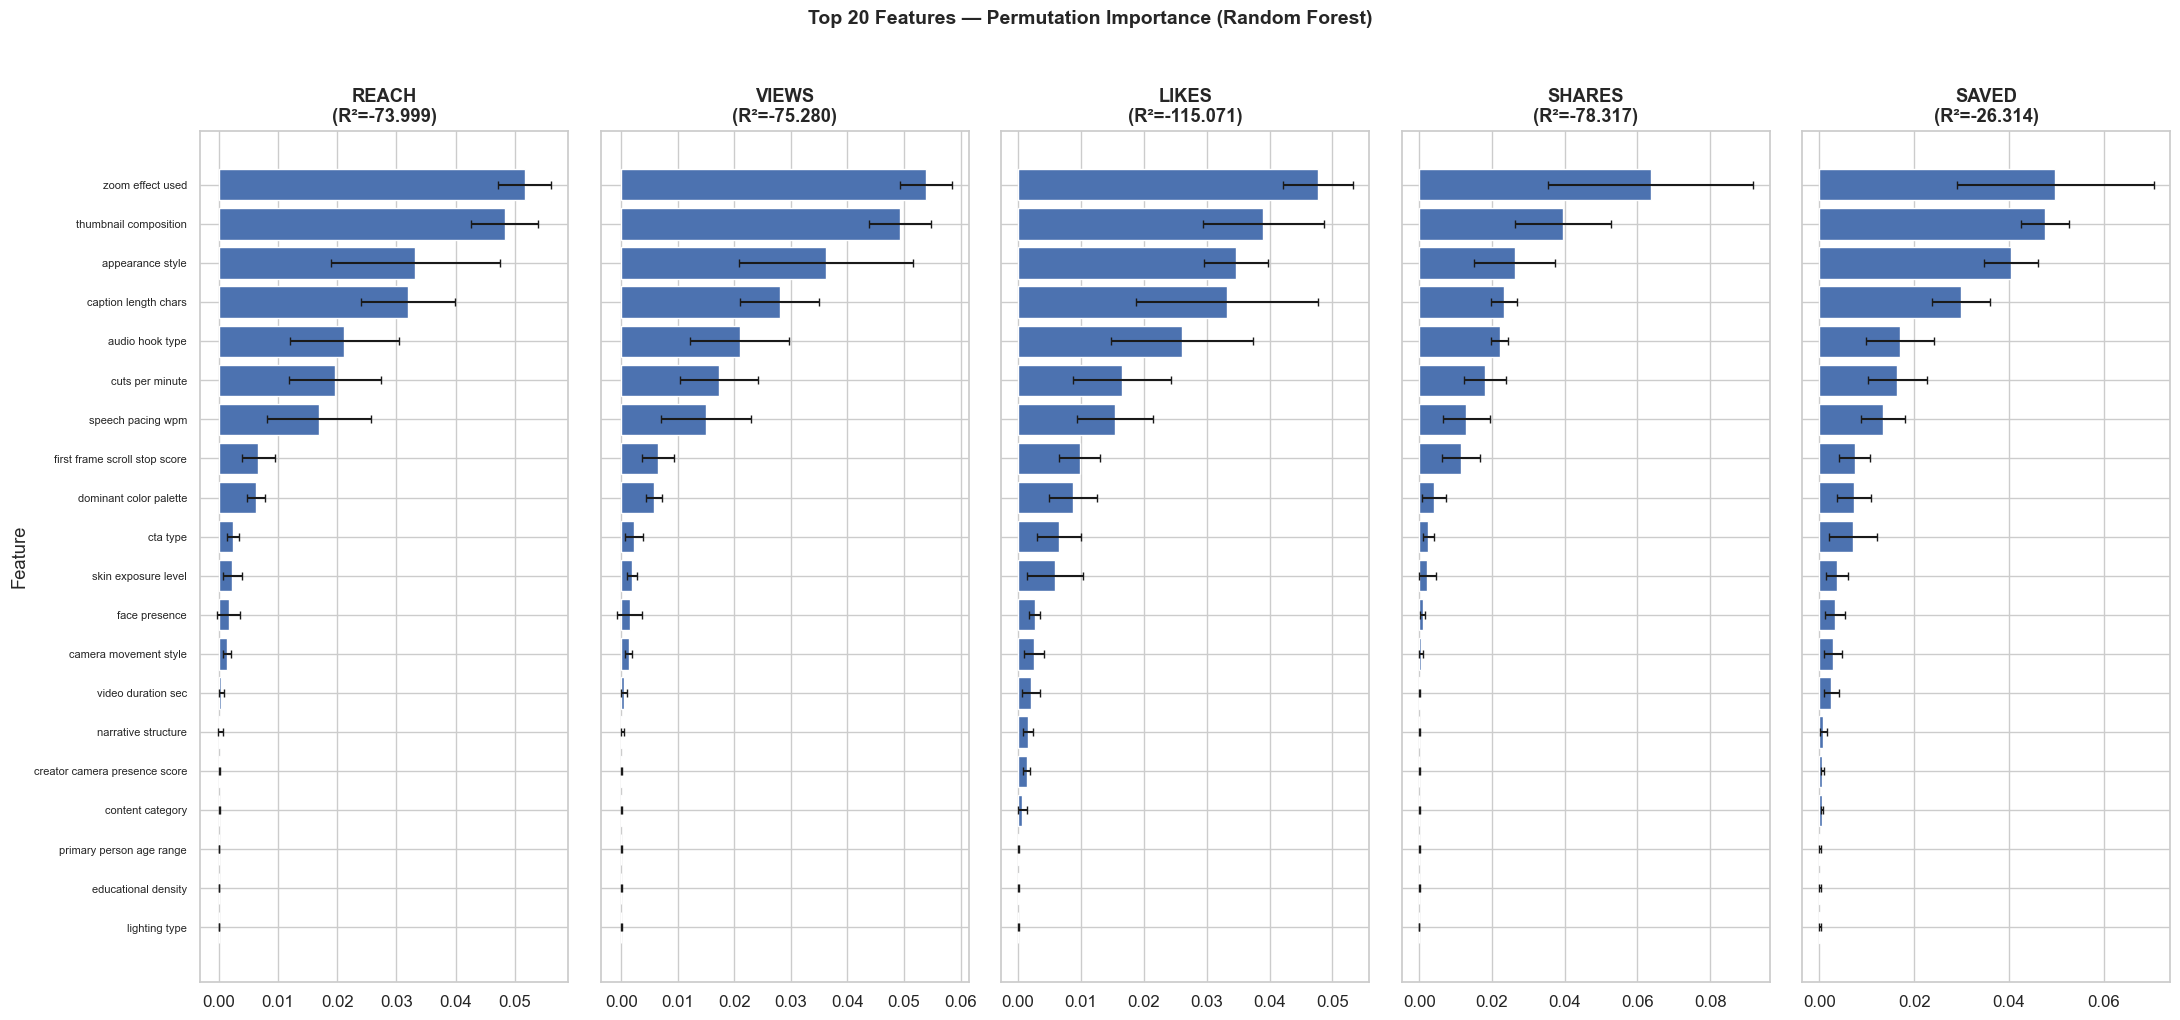

In [5]:
fig, axes = plt.subplots(1, len(target_metrics), figsize=(22, 10), sharey=True)
for ax, metric in zip(axes, target_metrics):
    imp = rf_results[metric]["imp"].head(20)
    cv_r2 = rf_results[metric]["cv_r2"].mean()
    ax.barh(range(len(imp)), imp["importance_mean"], 
            xerr=imp["importance_std"], color="#4C72B0", edgecolor="white", capsize=3)
    ax.set_yticks(range(len(imp)))
    labels = [f.replace("_", " ")[:30] for f in imp["feature"]]
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(f"{metric.upper()}\n(R²={cv_r2:.3f})", fontweight="bold")
    if ax == axes[0]:
        ax.set_ylabel("Feature")

fig.suptitle("Top 20 Features — Permutation Importance (Random Forest)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 4. Ranking Consolidado — Top Features (média dos ranks entre métodos e métricas)

TOP 25 FEATURES — RANKING CONSOLIDADO
(média dos ranks de Spearman + RF, across 5 métricas)
   1. caption_length_chars                      avg_rank=  2.7  (best: likes)
   2. speech_pacing_wpm                         avg_rank=  3.2  (best: shares)
   3. cuts_per_minute                           avg_rank=  4.6  (best: reach)
   4. appearance_style                          avg_rank=  6.9  (best: reach)
   5. skin_exposure_level                       avg_rank= 10.1  (best: views)
   6. first_frame_scroll_stop_score             avg_rank= 11.9  (best: saved)
   7. creator_camera_presence_score             avg_rank= 12.5  (best: shares)
   8. zoom_effect_used                          avg_rank= 14.0  (best: saved)
   9. narrative_structure                       avg_rank= 15.4  (best: saved)
  10. target_audience_intent                    avg_rank= 15.6  (best: reach)
  11. face_presence                             avg_rank= 17.0  (best: reach)
  12. overall_provocation_score                 

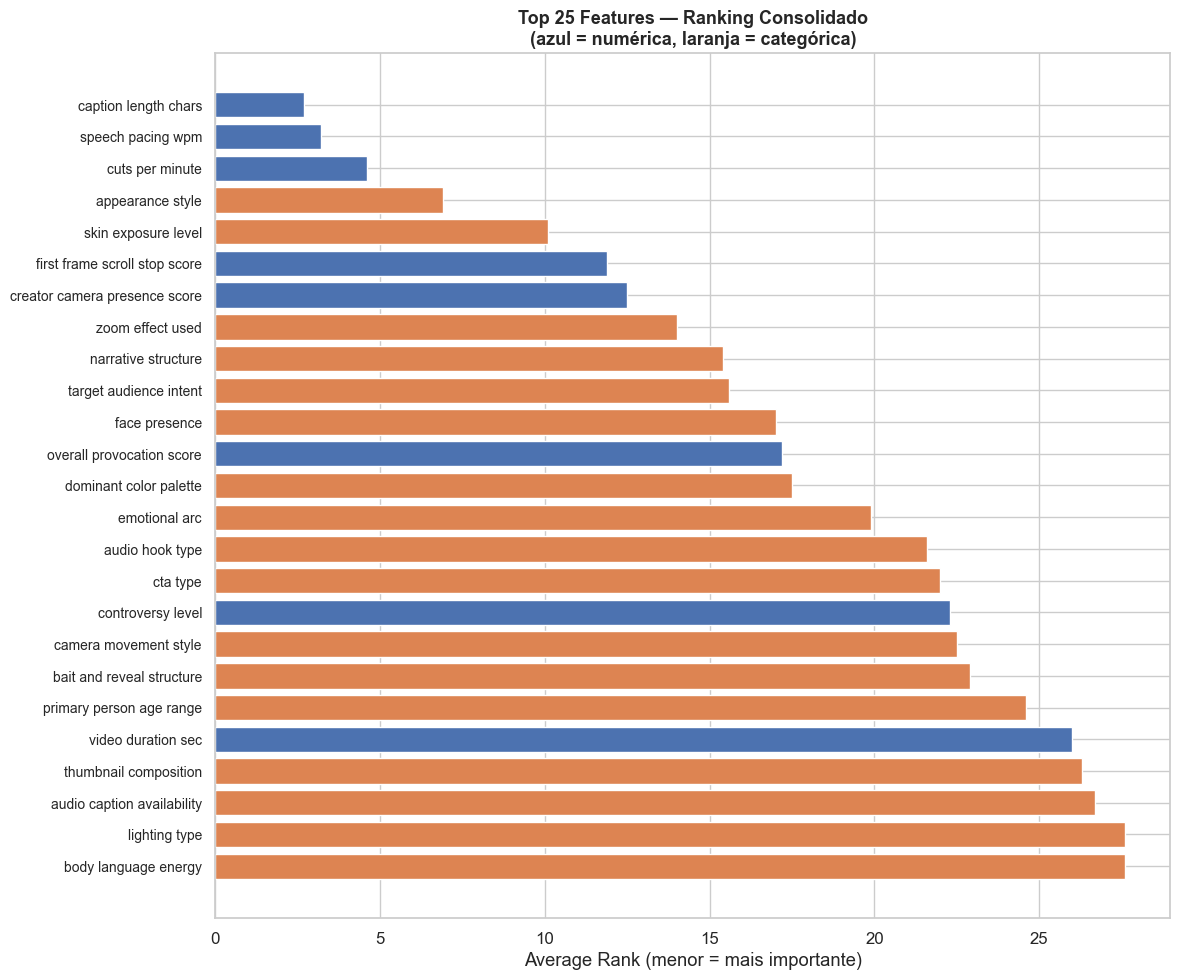

In [6]:
rank_data = []

for metric in target_metrics:
    sp = spearman_results[metric].reset_index().rename(columns={"index": "feature"})
    sp["spearman_rank"] = range(1, len(sp) + 1)
    
    rf_imp = rf_results[metric]["imp"].reset_index(drop=True)
    rf_imp["rf_rank"] = range(1, len(rf_imp) + 1)
    
    merged = sp[["feature", "spearman_rank"]].merge(
        rf_imp[["feature", "rf_rank"]], on="feature"
    )
    merged["avg_rank"] = (merged["spearman_rank"] + merged["rf_rank"]) / 2
    merged["metric"] = metric
    rank_data.append(merged)

all_ranks = pd.concat(rank_data)
overall = all_ranks.groupby("feature")["avg_rank"].mean().sort_values()

print("=" * 60)
print("TOP 25 FEATURES — RANKING CONSOLIDADO")
print("(média dos ranks de Spearman + RF, across 5 métricas)")
print("=" * 60)
for i, (feat, rank) in enumerate(overall.head(25).items(), 1):
    per_metric = all_ranks[all_ranks["feature"] == feat].set_index("metric")["avg_rank"]
    best_metric = per_metric.idxmin()
    print(f"  {i:2d}. {feat:40s}  avg_rank={rank:5.1f}  (best: {best_metric})")

fig, ax = plt.subplots(figsize=(12, 10))
top25 = overall.head(25)
colors = ["#4C72B0" if f in available_num else "#DD8452" for f in top25.index]
ax.barh(range(len(top25)), top25.values, color=colors, edgecolor="white")
ax.set_yticks(range(len(top25)))
ax.set_yticklabels([f.replace("_", " ") for f in top25.index], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("Average Rank (menor = mais importante)")
ax.set_title("Top 25 Features — Ranking Consolidado\n(azul = numérica, laranja = categórica)",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

## 5. Heatmap: Top Features × Métricas (Spearman)

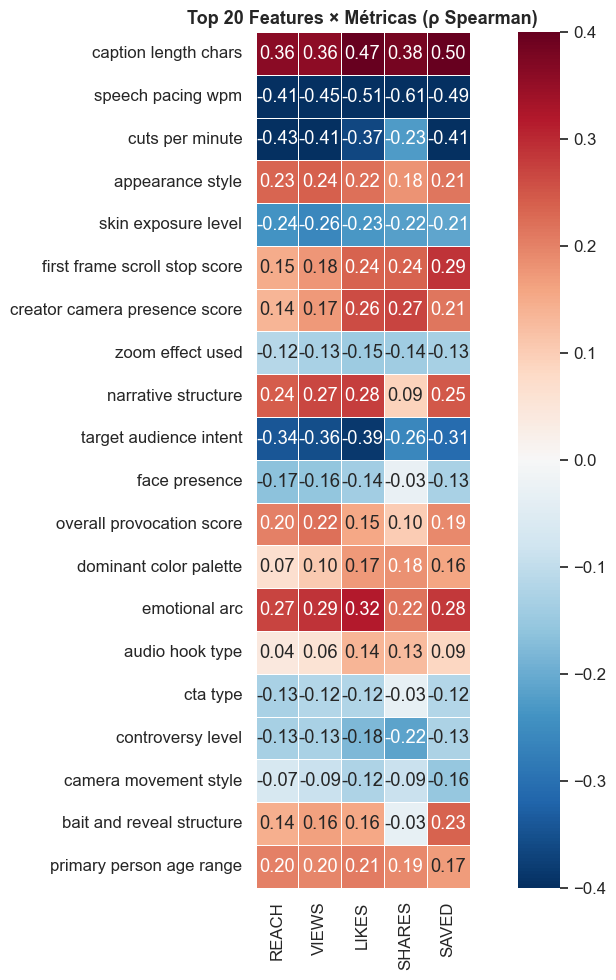

In [7]:
top_feats = list(overall.head(20).index)

heatmap_data = pd.DataFrame(index=top_feats, columns=target_metrics, dtype=float)
for metric in target_metrics:
    for feat in top_feats:
        if feat in spearman_results[metric].index:
            heatmap_data.loc[feat, metric] = spearman_results[metric].loc[feat, "rho"]

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(heatmap_data.astype(float), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-0.4, vmax=0.4, square=True, linewidths=0.5, ax=ax,
            yticklabels=[f.replace("_", " ") for f in top_feats],
            xticklabels=[m.upper() for m in target_metrics])
ax.set_title("Top 20 Features × Métricas (ρ Spearman)", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()